<a href="https://colab.research.google.com/github/dudekulapeeravali2537sse-bot/ITA0616/blob/main/EXP_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IRIS FLOWER DATASET
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset Shape: (150, 5)

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64

Model Training Completed Successfully!

ACTUAL VS PREDICTED RESULTS
   Actual Species Predicted Species
0          setosa            setosa
1       virginica         virginica
2      versicolor        versicolor
3      versicolor        versicolor
4          set

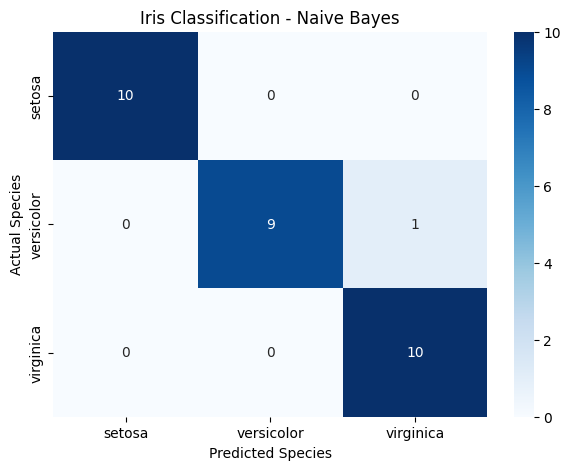


NEW FLOWER DETAILS
Sepal Length: 5.1 cm
Sepal Width: 3.5 cm
Petal Length: 1.4 cm
Petal Width: 0.2 cm

Predicted Flower Species: setosa

PREDICTION PROBABILITIES
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


In [1]:

# IRIS FLOWER CLASSIFICATION USING NAIVE BAYES

# Step 1: Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report

# Step 2: Load Iris Dataset
iris = load_iris()

X = iris.data
y = iris.target

# Step 3: Convert Dataset into DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df['Species'] = iris.target_names[y]

print("IRIS FLOWER DATASET")
print(df.head())

print("\nDataset Shape:", df.shape)

# Step 4: Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Step 5: Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 6: Create Gaussian Naive Bayes Classifier
model = GaussianNB()

# Step 7: Train the Model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 8: Predict Test Data
y_pred = model.predict(X_test)

print("\nACTUAL VS PREDICTED RESULTS")

results = pd.DataFrame({
    'Actual Species': iris.target_names[y_test],
    'Predicted Species': iris.target_names[y_pred]
})

print(results)

# Step 9: Calculate Model Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL ACCURACY")
print("Accuracy: {:.2f}%".format(accuracy * 100))

# Step 10: Classification Report
print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Step 11: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Iris Classification - Naive Bayes")
plt.show()

# Step 12: Predict a New Iris Flower
# Sepal Length = 5.1
# Sepal Width = 3.5
# Petal Length = 1.4
# Petal Width = 0.2

new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

prediction = model.predict(new_flower)

print("\nNEW FLOWER DETAILS")
print("Sepal Length: 5.1 cm")
print("Sepal Width: 3.5 cm")
print("Petal Length: 1.4 cm")
print("Petal Width: 0.2 cm")

print("\nPredicted Flower Species:",
      iris.target_names[prediction[0]])

# Step 13: Predict Probability for Each Species
probabilities = model.predict_proba(new_flower)

print("\nPREDICTION PROBABILITIES")

for species, probability in zip(
    iris.target_names, probabilities[0]
):
    print("{}: {:.2f}%".format(
        species, probability * 100
    ))
